# Traffic Sign Recognizer (GTSRB) - CNN in PyTorch

**Pipeline of this project (the same shape as almost every deep learning project):**

1. **Setup** - libraries, settings, paths
2. **Data understanding** - look at the CSVs, class balance, sample images
3. **Data preparation** - load images, split into train/validation, augmentation
4. **Model** - define the CNN
5. **Training** - train, watch the curves
6. **Evaluation** - accuracy on unseen test data, confusion matrix, error analysis
7. **Real-world test** - your own phone photos
8. **Saving** - keep the model for the Streamlit app

Run the cells from top to bottom. Change the settings in Step 2 if your PC is too slow or has room to spare.

## Part 1: Setup

In [2]:
## Step 1: Install the extra libraries (run once; if pip installs anything, restart the kernel afterwards)
%pip install torch torchvision scikit-learn seaborn pillow

Note: you may need to restart the kernel to use updated packages.


In [3]:
## Step 2: Imports and project settings (everything you may want to tune is in this cell)
import os, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# --- path to the unzipped dataset (folder that contains Train, Test, Meta and the 3 CSVs)
DATA_DIR = Path(r"C:\Users\Tanmay\Desktop\Traffic sign recognizer\Traffic sign recognizer")

# --- how much data to use (lower these if your PC is slow, raise them if it is fast)
IMAGES_PER_CLASS = 200      # None = use every training image
TEST_IMAGES = 3000          # how many official test images to evaluate on (None = all ~12,600)

# --- model / training settings
IMG_SIZE = 32               # every image is resized to IMG_SIZE x IMG_SIZE
BATCH_SIZE = 64
EPOCHS = 12
LEARNING_RATE = 1e-3
SEED = 42

# --- reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("Dataset folder exists:", DATA_DIR.exists())
print("Inside it:", [p.name for p in DATA_DIR.iterdir()])

Device: cpu
Dataset folder exists: True
Inside it: ['.ipynb_checkpoints', 'cache_train_200_32.npz', 'Meta', 'Meta.csv', 'Test', 'Test.csv', 'traffic_sign_recognizer.ipynb', 'Train', 'Train.csv']


## Part 2: Data understanding

In [4]:
## Step 3: Read the CSV files (they list every image, its class and the sign's bounding box)
train_df = pd.read_csv(DATA_DIR / "Train.csv")
test_df = pd.read_csv(DATA_DIR / "Test.csv")
meta_df = pd.read_csv(DATA_DIR / "Meta.csv")

print("Train rows:", train_df.shape, "| Test rows:", test_df.shape, "| Meta rows:", meta_df.shape)
print("Train columns:", list(train_df.columns))
train_df.head()

Train rows: (39209, 8) | Test rows: (12630, 8) | Meta rows: (43, 5)
Train columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


In [5]:
## Step 4: Human-readable names for the 43 classes
CLASS_NAMES = {
    0: "Speed limit (20 km/h)", 1: "Speed limit (30 km/h)", 2: "Speed limit (50 km/h)",
    3: "Speed limit (60 km/h)", 4: "Speed limit (70 km/h)", 5: "Speed limit (80 km/h)",
    6: "End of speed limit (80 km/h)", 7: "Speed limit (100 km/h)", 8: "Speed limit (120 km/h)",
    9: "No passing", 10: "No passing for vehicles over 3.5 t", 11: "Right-of-way at next intersection",
    12: "Priority road", 13: "Yield", 14: "Stop", 15: "No vehicles",
    16: "Vehicles over 3.5 t prohibited", 17: "No entry", 18: "General caution",
    19: "Dangerous curve to the left", 20: "Dangerous curve to the right", 21: "Double curve",
    22: "Bumpy road", 23: "Slippery road", 24: "Road narrows on the right", 25: "Road work",
    26: "Traffic signals", 27: "Pedestrians", 28: "Children crossing", 29: "Bicycles crossing",
    30: "Beware of ice/snow", 31: "Wild animals crossing", 32: "End of all speed and passing limits",
    33: "Turn right ahead", 34: "Turn left ahead", 35: "Ahead only", 36: "Go straight or right",
    37: "Go straight or left", 38: "Keep right", 39: "Keep left", 40: "Roundabout mandatory",
    41: "End of no passing", 42: "End of no passing by vehicles over 3.5 t",
}
NUM_CLASSES = len(CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)

Number of classes: 43


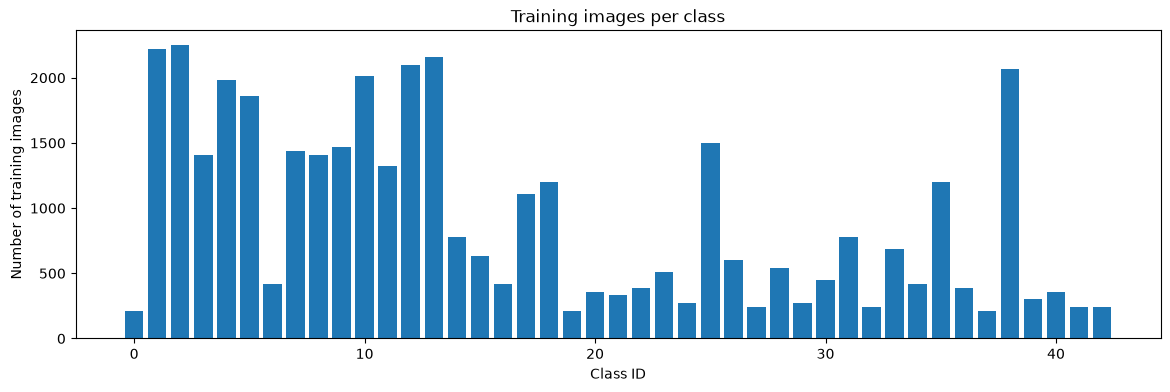

Smallest class: 210 images | Largest class: 2250 images
Imbalance ratio (largest / smallest): 10.7x


In [6]:
## Step 5: Check class balance (an imbalanced dataset can fool a model into ignoring rare classes)
class_counts = train_df["ClassId"].value_counts().sort_index()

plt.figure(figsize=(14, 4))
plt.bar(class_counts.index, class_counts.values)
plt.xlabel("Class ID")
plt.ylabel("Number of training images")
plt.title("Training images per class")
plt.show()

print("Smallest class:", class_counts.min(), "images | Largest class:", class_counts.max(), "images")
print("Imbalance ratio (largest / smallest): %.1fx" % (class_counts.max() / class_counts.min()))

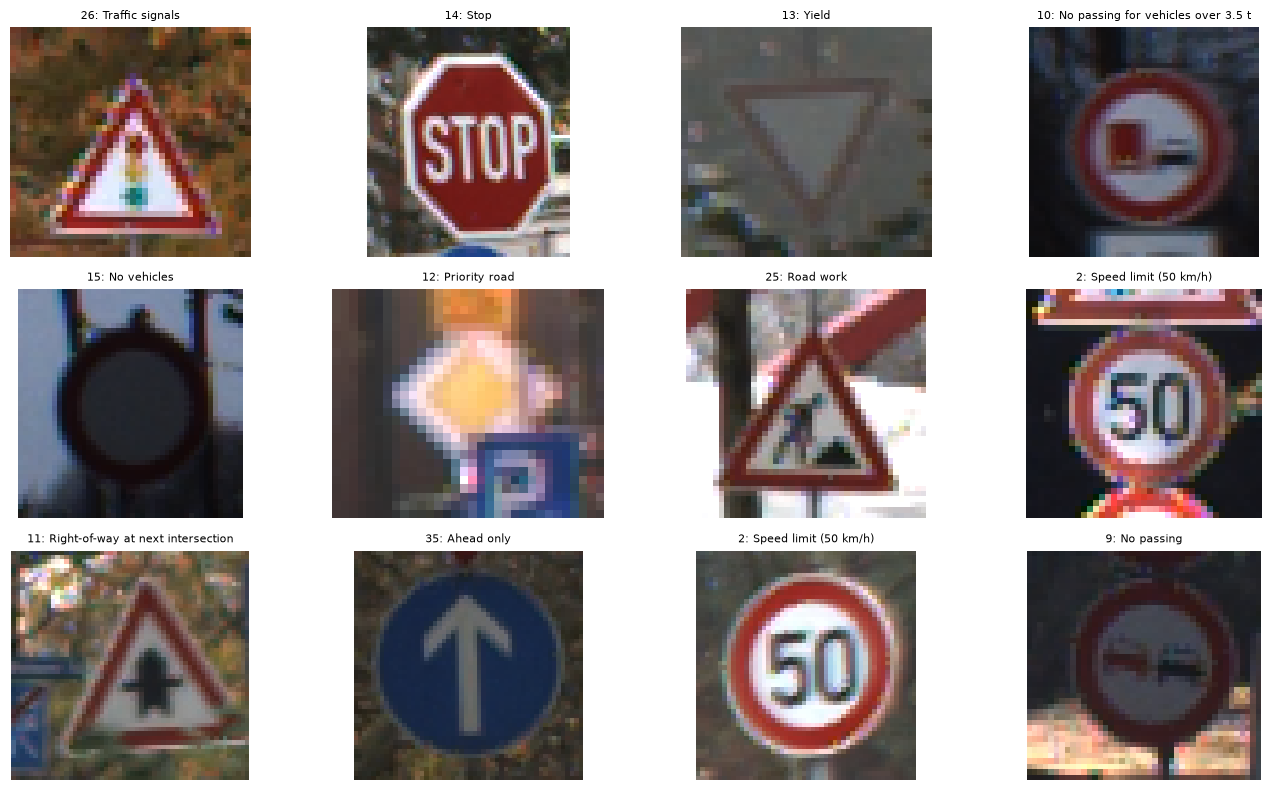

Image sizes vary a lot: width from 25 to 243


In [7]:
## Step 6: Look at some real training images (always look at your data before modelling)
sample = train_df.sample(12, random_state=SEED)

plt.figure(figsize=(14, 8))
for i, (_, row) in enumerate(sample.iterrows()):
    img = Image.open(DATA_DIR / row["Path"])
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f"{row['ClassId']}: {CLASS_NAMES[row['ClassId']]}", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

print("Image sizes vary a lot: width from", train_df["Width"].min(), "to", train_df["Width"].max())

## Part 3: Data preparation

In [8]:
## Step 7: Pick a balanced subset of the training data (keeps training light on a weak PC)
if IMAGES_PER_CLASS is None:
    subset_df = train_df.copy()
else:
    subset_df = pd.concat(
        [g.sample(min(len(g), IMAGES_PER_CLASS), random_state=SEED) for _, g in train_df.groupby("ClassId")]
    ).reset_index(drop=True)

print("Using", len(subset_df), "of", len(train_df), "training images")
print("Images per class now: min", subset_df["ClassId"].value_counts().min(),
      "| max", subset_df["ClassId"].value_counts().max())

Using 8600 of 39209 training images
Images per class now: min 200 | max 200


In [9]:
## Step 8: Load the images into memory (crop to the sign, resize, store as numbers)
def load_image(row):
    img = Image.open(DATA_DIR / row["Path"]).convert("RGB")
    img = img.crop((row["Roi.X1"], row["Roi.Y1"], row["Roi.X2"], row["Roi.Y2"]))   # remove background around the sign
    return np.array(img.resize((IMG_SIZE, IMG_SIZE)))

def load_dataframe(df, desc):
    start = time.time()
    images = np.stack([load_image(row) for _, row in df.iterrows()])
    labels = df["ClassId"].values.astype(np.int64)
    print(f"{desc}: loaded {len(images)} images in {time.time() - start:.0f}s -> array shape {images.shape}")
    return images, labels

# cache file so you do not need to reload images every time you restart
cache_file = Path(f"cache_train_{IMAGES_PER_CLASS}_{IMG_SIZE}.npz")

if cache_file.exists():
    data = np.load(cache_file)
    X_all, y_all = data["X"], data["y"]
    print("Loaded from cache:", X_all.shape)
else:
    X_all, y_all = load_dataframe(subset_df, "Train subset")
    np.savez_compressed(cache_file, X=X_all, y=y_all)

Loaded from cache: (8600, 32, 32, 3)


In [10]:
## Step 9: Split into training and validation sets (validation = data the model never trains on, used to track progress)
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED
)
print("Train:", X_train.shape, "| Validation:", X_val.shape)

Train: (6880, 32, 32, 3) | Validation: (1720, 32, 32, 3)


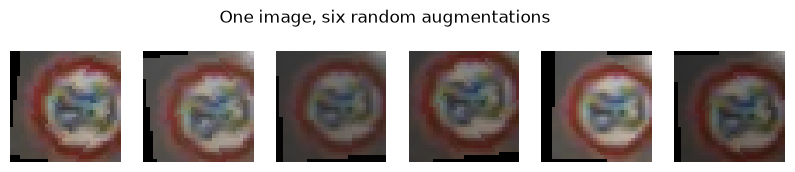

In [11]:
## Step 10: Data augmentation + PyTorch Dataset/DataLoader
# Augmentation = random small changes so the model sees "new" versions of each sign.
# NOTE: we do NOT flip images - a flipped "Turn left" would become "Turn right"!
normalize = transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))

train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    normalize,
])
eval_transform = transforms.Compose([transforms.ToPILImage(), transforms.ToTensor(), normalize])

class SignDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        return self.transform(self.images[idx]), int(self.labels[idx])

# num_workers=0 is the safest setting on Windows + Jupyter
train_loader = DataLoader(SignDataset(X_train, y_train, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(SignDataset(X_val, y_val, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# preview: the same sign, augmented 6 times
aug_preview = SignDataset(X_train[:1], y_train[:1], train_transform)
plt.figure(figsize=(10, 2))
for i in range(6):
    img_t, _ = aug_preview[0]
    plt.subplot(1, 6, i + 1)
    plt.imshow((img_t * 0.5 + 0.5).permute(1, 2, 0).numpy())
    plt.axis("off")
plt.suptitle("One image, six random augmentations")
plt.show()

## Part 4: The model

In [12]:
## Step 11: Define the CNN (3 convolution blocks to find patterns, then dense layers to decide the class)
class TrafficSignCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))   # 32x32 -> 16 -> 8 -> 4
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = TrafficSignCNN(NUM_CLASSES).to(DEVICE)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

# sanity check: one fake batch should give one score per class
print("Output shape:", model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)).shape)

Trainable parameters: 629291
Output shape: torch.Size([2, 43])


## Part 5: Training

In [13]:
## Step 12: Loss function, optimizer and the train/evaluate helper functions
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)   # halve the learning rate every 5 epochs

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += len(labels)
    return total_loss / total, correct / total

In [14]:
## Step 13: Train the model (keeps the best version based on validation accuracy)
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_state = 0.0, None

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    scheduler.step()

    for key, value in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
        history[key].append(value)
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time() - start:.0f}s")

model.load_state_dict(best_state)
print(f"\nBest validation accuracy: {best_val_acc:.3f}")

Epoch  1/12 | train loss 3.183 acc 0.127 | val loss 2.277 acc 0.295 | 16s
Epoch  2/12 | train loss 2.000 acc 0.370 | val loss 1.227 acc 0.624 | 18s
Epoch  3/12 | train loss 1.358 acc 0.555 | val loss 0.721 acc 0.787 | 17s
Epoch  4/12 | train loss 1.023 acc 0.665 | val loss 0.483 acc 0.867 | 16s
Epoch  5/12 | train loss 0.851 acc 0.719 | val loss 0.389 acc 0.890 | 17s
Epoch  6/12 | train loss 0.682 acc 0.778 | val loss 0.271 acc 0.918 | 15s
Epoch  7/12 | train loss 0.612 acc 0.799 | val loss 0.226 acc 0.942 | 15s
Epoch  8/12 | train loss 0.566 acc 0.816 | val loss 0.240 acc 0.933 | 21s
Epoch  9/12 | train loss 0.513 acc 0.829 | val loss 0.186 acc 0.952 | 18s
Epoch 10/12 | train loss 0.486 acc 0.841 | val loss 0.185 acc 0.942 | 17s
Epoch 11/12 | train loss 0.425 acc 0.862 | val loss 0.137 acc 0.969 | 22s
Epoch 12/12 | train loss 0.405 acc 0.869 | val loss 0.140 acc 0.969 | 19s

Best validation accuracy: 0.969


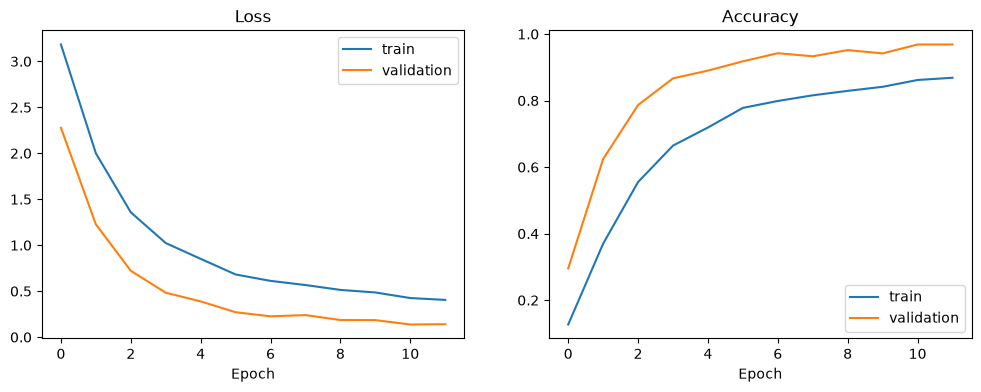

In [15]:
## Step 14: Plot the learning curves (are we learning? overfitting?)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.show()
# Reading it: if train accuracy keeps rising but validation stalls or falls, the model is overfitting.

## Part 6: Evaluation on the official test set

In [16]:
## Step 15: Load the official test images (never used in training, so this is the honest score)
if TEST_IMAGES is None or TEST_IMAGES >= len(test_df):
    test_subset = test_df.copy()
else:
    test_subset = test_df.sample(TEST_IMAGES, random_state=SEED).reset_index(drop=True)

X_test, y_test = load_dataframe(test_subset, "Test set")
test_loader = DataLoader(SignDataset(X_test, y_test, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

Test set: loaded 3000 images in 8s -> array shape (3000, 32, 32, 3)


In [17]:
## Step 16: Predict on the test set and compute accuracy
def get_predictions(loader):
    model.eval()
    preds, labels_all = [], []
    with torch.no_grad():
        for images, labels in loader:
            preds.extend(model(images.to(DEVICE)).argmax(1).cpu().numpy())
            labels_all.extend(labels.numpy())
    return np.array(preds), np.array(labels_all)

y_pred, y_true = get_predictions(test_loader)
print(f"Test accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%")

Test accuracy: 90.30%


In [18]:
## Step 17: Precision / recall per class (which signs does the model handle worst?)
report = classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                               target_names=[CLASS_NAMES[i] for i in range(NUM_CLASSES)],
                               output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T.iloc[:NUM_CLASSES]
print("5 weakest classes (by F1-score):")
report_df.sort_values("f1-score").head(5)[["precision", "recall", "f1-score", "support"]]

5 weakest classes (by F1-score):


,precision,recall,f1-score,support
Speed limit (20 km/h),0.500000,0.600000,0.545455,10.0
Speed limit (100 km/h),0.688889,0.632653,0.659574,98.0
Speed limit (80 km/h),0.776699,0.625000,0.692641,128.0
Speed limit (120 km/h),0.690909,0.752475,0.720379,101.0
Slippery road,0.659091,0.828571,0.734177,35.0


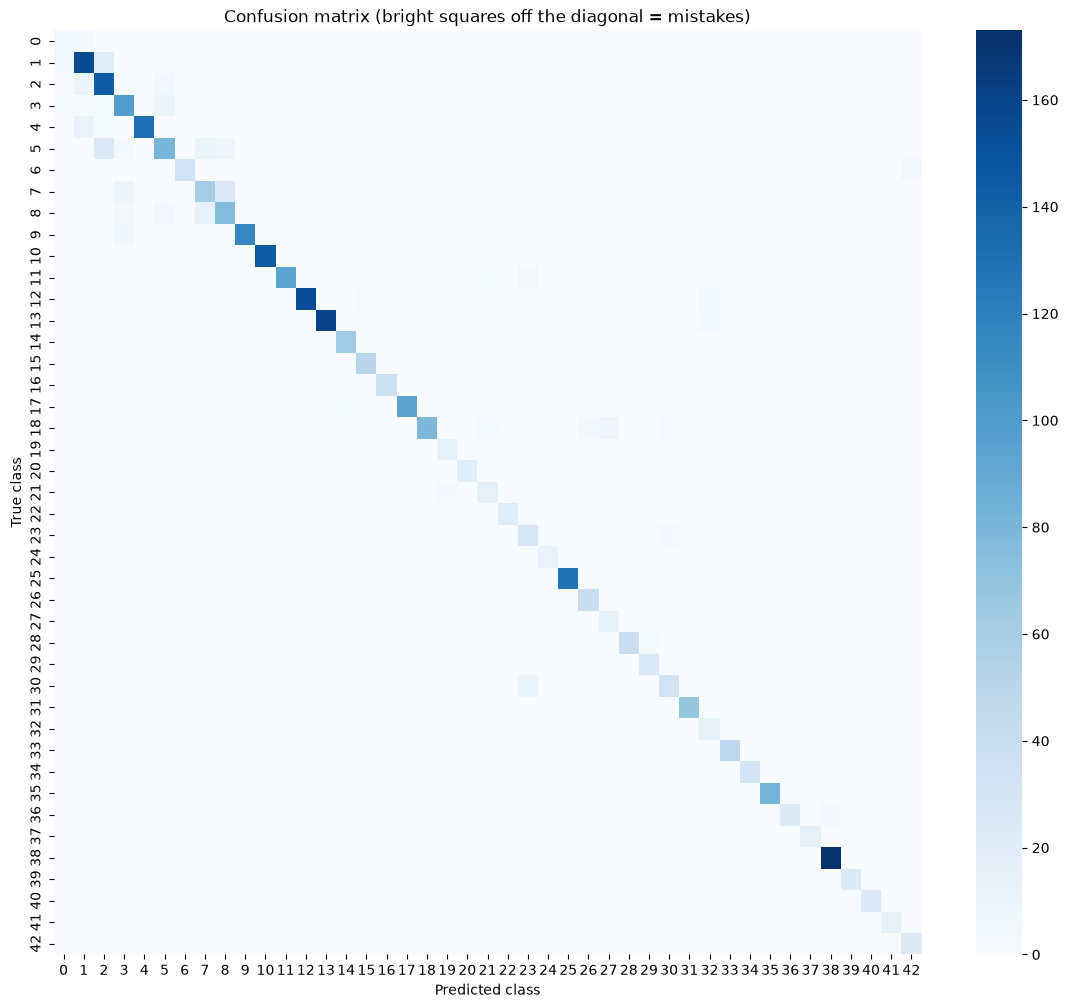

In [19]:
## Step 18: Confusion matrix (rows = real sign, columns = what the model predicted)
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap="Blues", cbar=True)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix (bright squares off the diagonal = mistakes)")
plt.show()

In [20]:
## Step 19: Which pairs of signs get confused the most? (error analysis - great to mention in interviews)
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)
top_pairs = np.dstack(np.unravel_index(np.argsort(cm_errors.ravel())[::-1][:8], cm_errors.shape))[0]

print("Most confused pairs (real -> predicted):")
for true_id, pred_id in top_pairs:
    if cm_errors[true_id, pred_id] > 0:
        print(f"  {cm_errors[true_id, pred_id]:3d} times: {CLASS_NAMES[true_id]}  ->  {CLASS_NAMES[pred_id]}")

Most confused pairs (real -> predicted):
   25 times: Speed limit (80 km/h)  ->  Speed limit (50 km/h)
   25 times: Speed limit (100 km/h)  ->  Speed limit (120 km/h)
   20 times: Speed limit (30 km/h)  ->  Speed limit (50 km/h)
   14 times: Speed limit (120 km/h)  ->  Speed limit (100 km/h)
   11 times: Speed limit (70 km/h)  ->  Speed limit (30 km/h)
   10 times: Beware of ice/snow  ->  Slippery road
   10 times: Speed limit (50 km/h)  ->  Speed limit (30 km/h)
   10 times: Speed limit (60 km/h)  ->  Speed limit (80 km/h)


291 wrong out of 3000


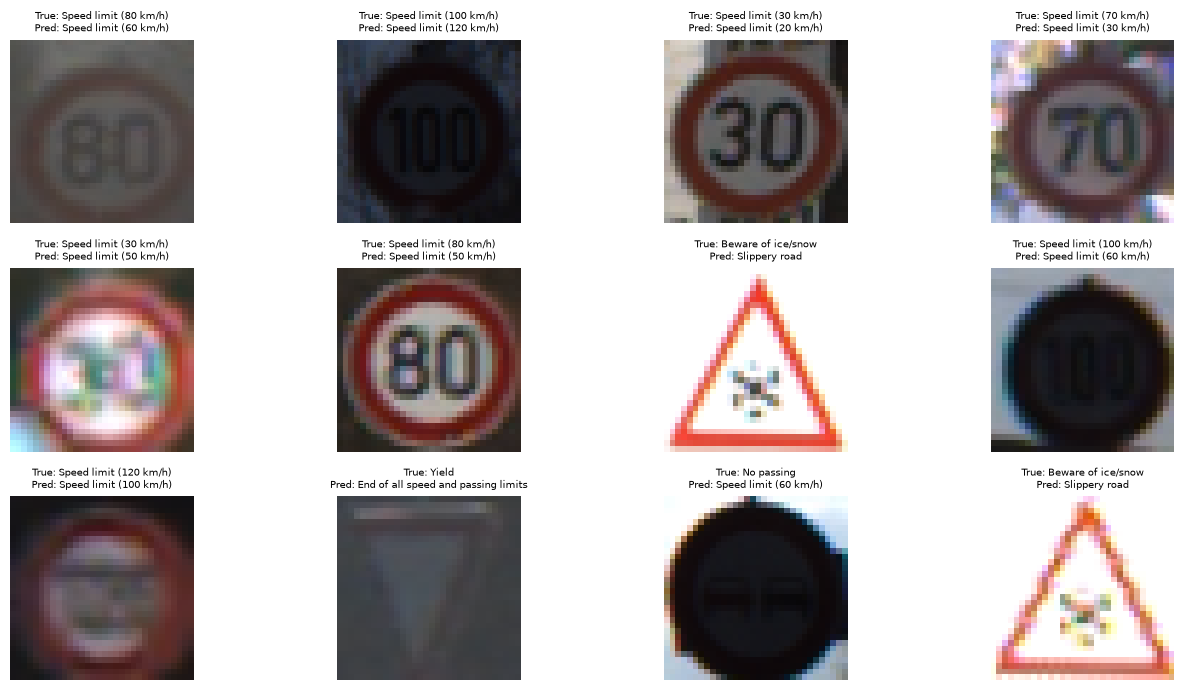

In [21]:
## Step 20: Look at actual mistakes
wrong = np.where(y_pred != y_true)[0]
print(f"{len(wrong)} wrong out of {len(y_true)}")

plt.figure(figsize=(14, 7))
for i, idx in enumerate(wrong[:12]):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[idx])
    plt.title(f"True: {CLASS_NAMES[y_true[idx]]}\nPred: {CLASS_NAMES[y_pred[idx]]}", fontsize=7)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Part 7: Real-world test with your own photos

Create a folder named **my_photos** next to this notebook and put photos of traffic signs in it.
For best results, crop each photo so the sign fills most of the picture (this model classifies a sign, it does not find one in a street scene).
Remember: it was trained on German signs, so Indian signs may be wrong or unrecognised. That is a useful thing to report, not a failure.

In [22]:
## Step 21: Function to predict the sign in any image file (returns the top 3 guesses)
def predict_image(path, top_k=3):
    img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    tensor = eval_transform(np.array(img)).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(tensor), dim=1)[0]
    top_probs, top_ids = probs.topk(top_k)
    return img, [(CLASS_NAMES[i.item()], p.item()) for i, p in zip(top_ids, top_probs)]

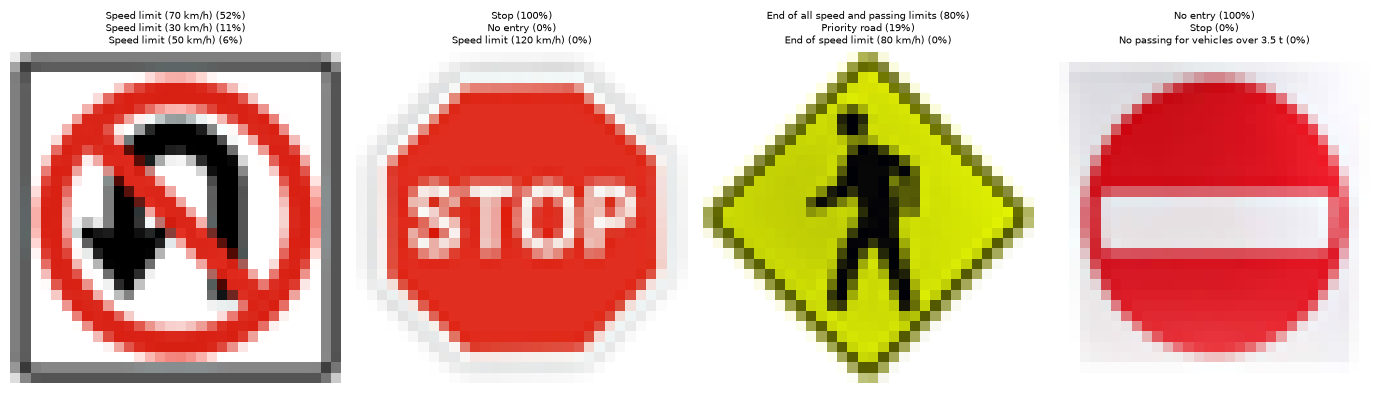

In [29]:
## Step 22: Run it on the photos in the my_photos folder
photo_dir = Path("my_photos")
photo_dir.mkdir(exist_ok=True)
photos = [p for p in photo_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]

if not photos:
    print("my_photos is empty - add some sign photos and re-run this cell.")
else:
    plt.figure(figsize=(14, 4 * ((len(photos) + 3) // 4)))
    for i, p in enumerate(photos):
        img, guesses = predict_image(p)
        plt.subplot((len(photos) + 3) // 4, 4, i + 1)
        plt.imshow(img)
        plt.title("\n".join(f"{n} ({pr * 100:.0f}%)" for n, pr in guesses), fontsize=7)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## Part 8: Save the model for the Streamlit app

In [27]:
## Step 23: Save the trained model, class names and settings
torch.save({
    "state_dict": model.state_dict(),
    "class_names": CLASS_NAMES,
    "img_size": IMG_SIZE,
    "num_classes": NUM_CLASSES,
}, "traffic_sign_cnn.pth")
print("Saved traffic_sign_cnn.pth")

Saved traffic_sign_cnn.pth


In [28]:
## Step 24: Final summary (copy these numbers into your README / resume)
print("Images used for training:", len(X_train), "| validation:", len(X_val), "| test:", len(X_test))
print(f"Best validation accuracy: {best_val_acc * 100:.2f}%")
print(f"Test accuracy:            {accuracy_score(y_true, y_pred) * 100:.2f}%")
print("Model parameters:", sum(p.numel() for p in model.parameters()))

Images used for training: 6880 | validation: 1720 | test: 3000
Best validation accuracy: 96.86%
Test accuracy:            90.30%
Model parameters: 629291


In [30]:
import sys
print(sys.executable)

C:\Users\Tanmay\AppData\Local\Programs\Python\Python314\python.exe
